In [3]:
import math
import random
from dataclasses import dataclass
import matplotlib.pyplot as plt

# Part 1 - cities and tour functions
def make_cities(n=40, seed=7):
    rng = random.Random(seed)
    return [(rng.random(), rng.random()) for _ in range(n)]

def dist(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])

def tour_length(cities, tour):
    total = 0
    for i in range(len(tour)):
        total += dist(cities[tour[i]], cities[tour[(i + 1) % len(tour)]])
    return total

def is_valid_tour(tour, n):
    return len(tour) == n and set(tour) == set(range(n))

def random_tour(n, rng):
    tour = list(range(n))
    rng.shuffle(tour)
    return tour

def nearest_neighbor_tour(cities, start=0):
    unvisited = set(range(len(cities)))
    tour = [start]
    unvisited.remove(start)
    while unvisited:
        next_city = min(unvisited, key=lambda j: dist(cities[tour[-1]], cities[j]))
        tour.append(next_city)
        unvisited.remove(next_city)
    return tour

In [4]:
# Part 2 - change a tour
def two_opt_swap(tour, i, k):
    return tour[:i] + tour[i:k + 1][::-1] + tour[k + 1:]

def random_two_opt_neighbor(tour, rng):
    i, k = sorted(rng.sample(range(len(tour)), 2))
    return two_opt_swap(tour, i, k)

In [5]:
# Part 3 - graphs
def plot_tour(cities, tour, title):
    route = tour + [tour[0]]
    plt.figure(figsize=(6, 6))
    plt.plot([cities[i][0] for i in route],
             [cities[i][1] for i in route], 'o-')
    plt.title(title)
    plt.axis('equal')
    plt.show()

def plot_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history)
    plt.title(title)
    plt.xlabel('Iteration / Generation')
    plt.ylabel('Best tour length')
    plt.show()

Nearest neighbor: 6.0214


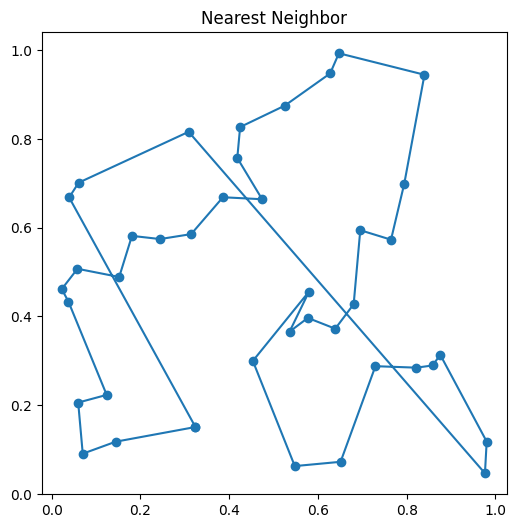

In [6]:
# Part 4 - nearest neighbor
cities = make_cities(40, seed=7)
nn_tour = nearest_neighbor_tour(cities)
nn_len = tour_length(cities, nn_tour)

print(f'Nearest neighbor: {nn_len:.4f}')
plot_tour(cities, nn_tour, 'Nearest Neighbor')

SA iteration 2000: best = 6.0214
SA iteration 4000: best = 5.6676
SA iteration 6000: best = 5.4278
SA iteration 8000: best = 5.3626
SA iteration 10000: best = 5.3626
SA iteration 12000: best = 5.3626
SA iteration 14000: best = 5.3626
SA iteration 16000: best = 5.3626
SA iteration 18000: best = 5.3626
SA iteration 20000: best = 5.3626
SA best: 5.3626
SA improvement: 10.94%


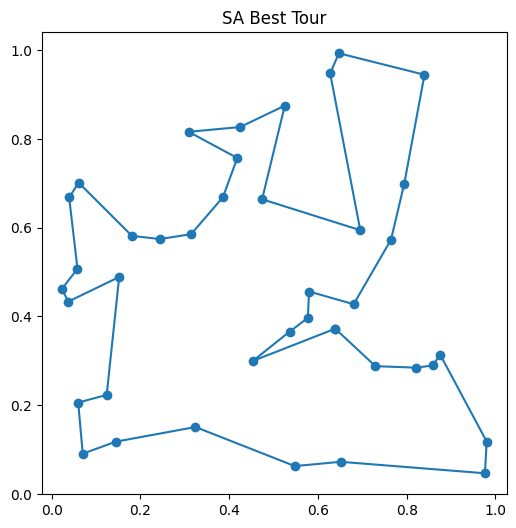

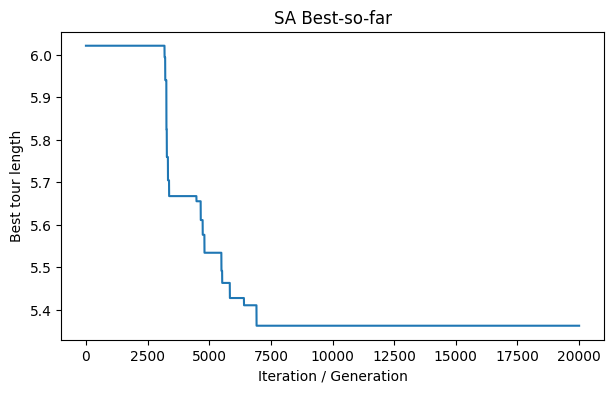

In [7]:
# Part 5A - simulated annealing
@dataclass
class SAConfig:
    iters: int = 20000
    t0: float = 0.2
    alpha: float = 0.9995
    seed: int = 123
    report_every: int = 2000

def simulated_annealing_tsp(cities, init_tour, cfg):
    rng = random.Random(cfg.seed)
    assert is_valid_tour(init_tour, len(cities))

    cur_tour = init_tour[:]
    cur_len = tour_length(cities, cur_tour)
    best_tour = cur_tour[:]
    best_len = cur_len

    history = [best_len]
    accepted = []
    rejected = []
    T = cfg.t0

    for it in range(cfg.iters):
        cand_tour = random_two_opt_neighbor(cur_tour, rng)
        cand_len = tour_length(cities, cand_tour)
        delta = cand_len - cur_len

        # Better paths are always accepted
        accept = delta <= 0 or rng.random() < math.exp(-delta / max(T, 1e-12))

        if accept:
            accepted.append(delta)
            cur_tour, cur_len = cand_tour, cand_len
        else:
            rejected.append(delta)

        if cur_len < best_len:
            best_tour, best_len = cur_tour[:], cur_len

        history.append(best_len)
        T = max(T * cfg.alpha, 1e-12)

        if cfg.report_every and (it + 1) % cfg.report_every == 0:
            print(f'SA iteration {it + 1}: best = {best_len:.4f}')

    return best_tour, best_len, history, accepted, rejected

sa_cfg = SAConfig()

sa_best_tour, sa_best_len, sa_hist, accepted, rejected = simulated_annealing_tsp(
    cities, nn_tour, sa_cfg
)

print(f'SA best: {sa_best_len:.4f}')
print(f'SA improvement: {(nn_len - sa_best_len) / nn_len * 100:.2f}%')

assert is_valid_tour(sa_best_tour, len(cities))
plot_tour(cities, sa_best_tour, 'SA Best Tour')
plot_history(sa_hist, 'SA Best-so-far')

GA generation 50: best = 5.3672
GA generation 100: best = 5.3672
GA generation 150: best = 5.3672
GA generation 200: best = 5.3672
GA generation 250: best = 5.3672
GA generation 300: best = 5.3672
GA generation 350: best = 5.3672
GA generation 400: best = 5.3672
GA best: 5.3672
GA improvement: 10.86%


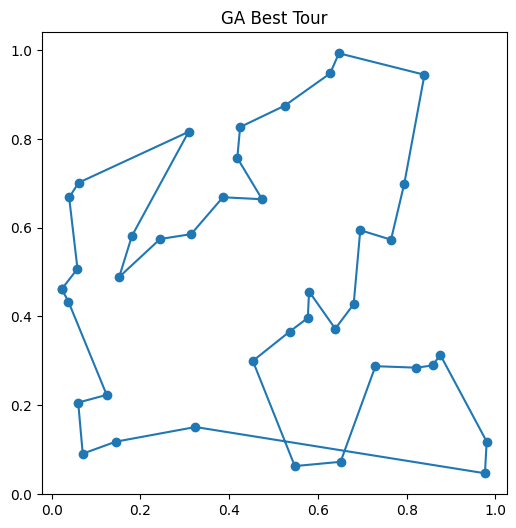

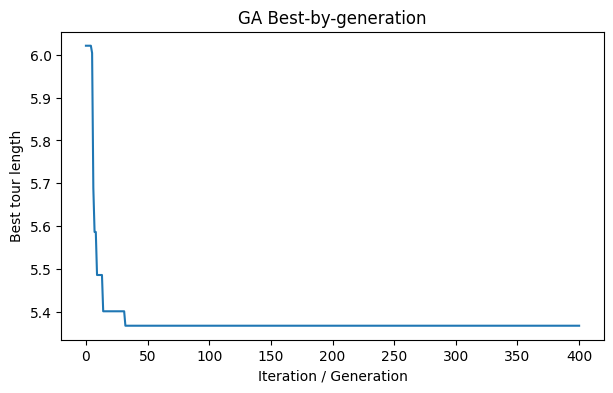

In [8]:
# Part 5B - genetic algorithm
@dataclass
class GAConfig:
    pop_size: int = 200
    generations: int = 400
    tournament_k: int = 5
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    elite_size: int = 5
    seed: int = 999
    report_every: int = 50

def tournament_select(pop, lengths, k, rng):
    choices = rng.sample(range(len(pop)), k)
    winner = min(choices, key=lambda i: lengths[i])
    return pop[winner][:]

def order_crossover_ox(parent1, parent2, rng):
    n = len(parent1)
    i, k = sorted(rng.sample(range(n), 2))
    child = [None] * n
    child[i:k + 1] = parent1[i:k + 1]

    # Fill the empty spots using the other parent
    remaining = [
        city for city in parent2[k + 1:] + parent2[:k + 1]
        if city not in child
    ]

    spots = list(range(k + 1, n)) + list(range(k + 1))

    for pos in spots:
        if child[pos] is None:
            child[pos] = remaining.pop(0)

    return child

def mutate_swap(tour, rng):
    new_tour = tour[:]
    i, j = rng.sample(range(len(tour)), 2)
    new_tour[i], new_tour[j] = new_tour[j], new_tour[i]
    return new_tour

def genetic_algorithm_tsp(cities, init_seed_tours, cfg):
    rng = random.Random(cfg.seed)
    n = len(cities)

    pop = [t[:] for t in init_seed_tours]
    assert all(is_valid_tour(t, n) for t in pop)

    while len(pop) < cfg.pop_size:
        pop.append(random_tour(n, rng))

    lengths = [tour_length(cities, t) for t in pop]
    best_idx = min(range(len(pop)), key=lambda i: lengths[i])
    best_tour = pop[best_idx][:]
    best_len = lengths[best_idx]

    history = [best_len]
    avg_history = [sum(lengths) / len(lengths)]
    diversity = [len(set(tuple(t) for t in pop)) / len(pop)]

    for gen in range(cfg.generations):
        elite = sorted(
            range(len(pop)), key=lambda i: lengths[i]
        )[:cfg.elite_size]

        next_pop = [pop[i][:] for i in elite]

        while len(next_pop) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)

            if rng.random() < cfg.crossover_rate:
                child = order_crossover_ox(p1, p2, rng)
            else:
                child = p1[:]

            if rng.random() < cfg.mutation_rate:
                child = mutate_swap(child, rng)

            next_pop.append(child)

        pop = next_pop
        lengths = [tour_length(cities, t) for t in pop]

        idx = min(range(len(pop)), key=lambda i: lengths[i])

        if lengths[idx] < best_len:
            best_len = lengths[idx]
            best_tour = pop[idx][:]

        history.append(best_len)
        avg_history.append(sum(lengths) / len(lengths))
        diversity.append(len(set(tuple(t) for t in pop)) / len(pop))

        if cfg.report_every and (gen + 1) % cfg.report_every == 0:
            print(f'GA generation {gen + 1}: best = {best_len:.4f}')

    assert is_valid_tour(best_tour, n)
    return best_tour, best_len, history, avg_history, diversity

ga_cfg = GAConfig()

ga_best_tour, ga_best_len, ga_hist, ga_avg, ga_div = genetic_algorithm_tsp(
    cities, [nn_tour], ga_cfg
)

print(f'GA best: {ga_best_len:.4f}')
print(f'GA improvement: {(nn_len - ga_best_len) / nn_len * 100:.2f}%')

plot_tour(cities, ga_best_tour, 'GA Best Tour')
plot_history(ga_hist, 'GA Best-by-generation')

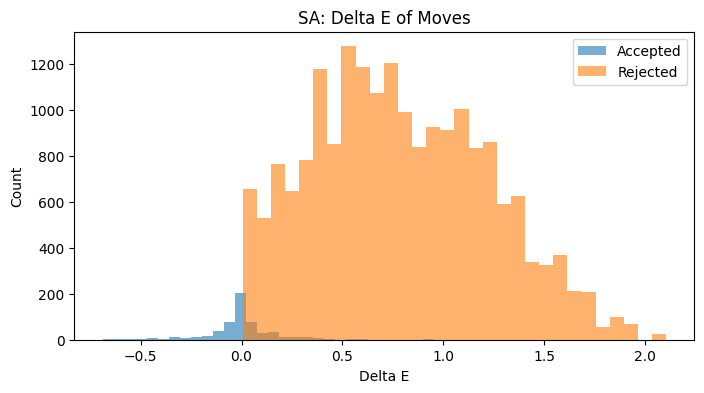

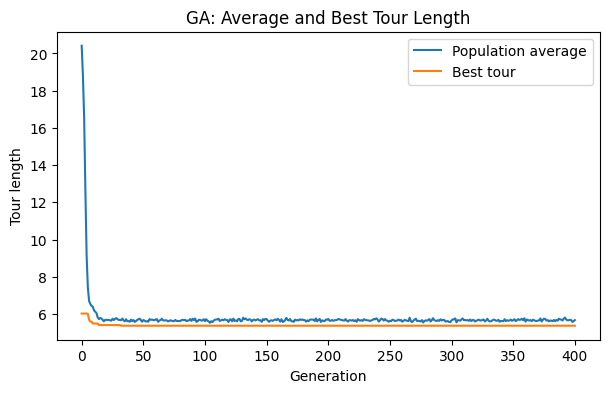

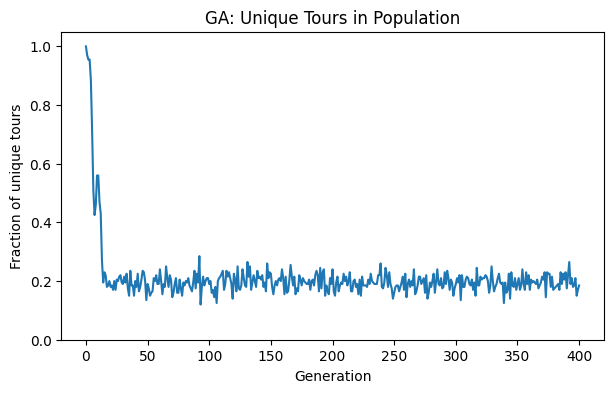

In [9]:
# Part 6 - extra graphs and comparison
plt.figure(figsize=(8, 4))
plt.hist(accepted, bins=30, alpha=0.6, label='Accepted')
plt.hist(rejected, bins=30, alpha=0.6, label='Rejected')
plt.title('SA: Delta E of Moves')
plt.xlabel('Delta E')
plt.ylabel('Count')
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ga_avg, label='Population average')
plt.plot(ga_hist, label='Best tour')
plt.title('GA: Average and Best Tour Length')
plt.xlabel('Generation')
plt.ylabel('Tour length')
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ga_div)
plt.title('GA: Unique Tours in Population')
plt.xlabel('Generation')
plt.ylabel('Fraction of unique tours')
plt.ylim(0, 1.05)
plt.show()

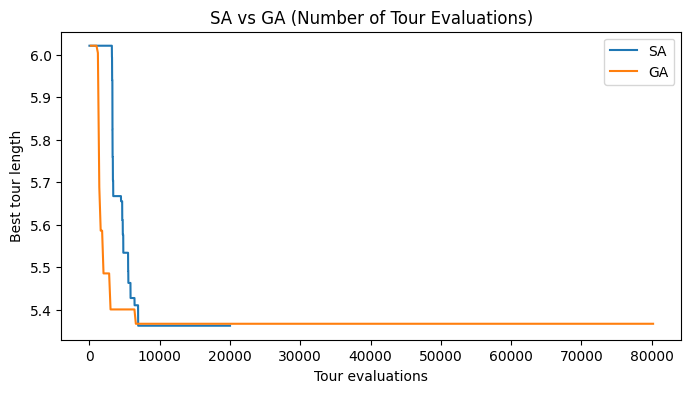


Final Results
NN: 6.0214
SA: 5.3626
GA: 5.3672
SA accepted moves: 576, rejected moves: 19424
GA unique tours: 1.00 at start, 0.18 at end


In [10]:
# Compare using the number of tour evaluations
plt.figure(figsize=(8, 4))
plt.plot(range(len(sa_hist)), sa_hist, label='SA')
plt.plot(
    [ga_cfg.pop_size * (i + 1) for i in range(len(ga_hist))],
    ga_hist,
    label='GA'
)
plt.title('SA vs GA (Number of Tour Evaluations)')
plt.xlabel('Tour evaluations')
plt.ylabel('Best tour length')
plt.legend()
plt.show()

print('\nFinal Results')
print(f'NN: {nn_len:.4f}')
print(f'SA: {sa_best_len:.4f}')
print(f'GA: {ga_best_len:.4f}')
print(f'SA accepted moves: {len(accepted)}, rejected moves: {len(rejected)}')
print(f'GA unique tours: {ga_div[0]:.2f} at start, {ga_div[-1]:.2f} at end')




In [11]:
# Check if each result improved at least 10%
for name, length in [('SA', sa_best_len), ('GA', ga_best_len)]:
    improvement = (nn_len - length) / nn_len * 100
    print(
        f'{name} improved {improvement:.2f}%:',
        'PASS' if improvement >= 10 else 'Below 10%'
    )

SA improved 10.94%: PASS
GA improved 10.86%: PASS
